# Trajectory annotation

**Linking every trajectory point to the conditions the moving object passed through.**

Movement data and context data are observed at different resolutions, and movement is far denser. AIS messages arrive within minutes; weather is reported hourly from a handful of coastal stations, and the sea state is forecast every three hours on a grid. So a vessel's position at 14:37, halfway between two stations and off the coast, has no wind and no wave measurement of its own.

Annotation supplies them, in two stages:

| | | |
|---|---|---|
| **1. Spatial** | across stations (or grid cells), one epoch at a time | *what was the wind / the wave height here, at that hour?* |
| **2. Temporal** | through time, at that position | *what was it here, at that minute?* |

Each stage has candidate methods, and each is compared by cross-validation. The method is that of Mehri et al. (2023), *A context-aware approach for vessels' trajectory prediction*, Ocean Engineering 282, 114916 ([doi](https://doi.org/10.1016/j.oceaneng.2023.114916)); its temporal stage (section 4.1: DLT, piecewise polynomial, spline) is implemented as published, and the spatial stage extends it, since that paper left the study of spatial interpolation out of its scope. The sea state is the context used by the CADP and CPLS-CLSTM papers (Mehri et al. 2025, *IJGI* 14(2), 58; Mehri et al. 2021, *IEEE Access* 9, 45600).

The method applies to any moving object (vessels, aircraft, vehicles, wildlife, pedestrians) and to any context measured at fixed points; the maritime data is one application, not the scope.

**Inputs:** the preprocessed AIS, weather and ocean tables written by `notebooks/01_preprocessing.ipynb` (the committed two-day sample is included).
**Outputs**, in `results/02_trajectory_annotation/<DATA>/`: `annotated_ais.parquet` (every AIS point of every vessel with eight context columns), `vessel_summary.csv`, the timing and cross-validation tables and the figures of this notebook.

Plots here are static images (so the notebook stays small and renders anywhere, GitHub's preview included); land is drawn from the preprocessed coastline, so nothing needs a network connection.

## Data

The notebook reads the **preprocessed** data (cleaned, median-filtered, in UTM zone 30N metres):

| table | what | resolution |
|---|---|---|
| `AIS/ais.parquet` | vessel positions, speed, course, vessel type | a message every few seconds to minutes |
| `Weather/weather.parquet` | 16 coastal stations: wind, temperature, pressure | hourly |
| `Ocean/ocean_<month>.parquet` | sea state on a regular grid (WAVEWATCH III, SHOM-IFREMER): sea level, wave height, wavelength, wave direction | **3-hourly**, one file per month |
| `Coastline/coastline.parquet` | land polygons, for the maps | |

**By default the notebook runs on the committed, preprocessed two-day sample**: 2015-11-09 and 2015-11-10 (UTC), Brest area, 565 vessels, 16 weather stations, hourly weather, 3-hourly sea state.

**To process the full archive** (October to December 2015 and February to March 2016, about 15 million AIS points), run `notebooks/01_preprocessing.ipynb` first (its download and preprocessing sections), then set `DATA = "full"` in the next cell, or start Jupyter with the environment variable `CATRAJ_DATA=full`.

**January 2016 is left out everywhere.** The Zenodo archive has no sea state for it: its `oc_january.csv` is a byte-for-byte copy of `oc_november.csv` (checked against Zenodo's published md5), so annotating January traffic with it would attach November's waves to January's ships. See the record, [zenodo.org/records/1167595](https://zenodo.org/records/1167595).

> Ray, C., Dr&eacute;o, R., Camossi, E., Jousselme, A.-L., Iphar, C. (2019). *Heterogeneous integrated dataset for Maritime Intelligence, Surveillance, and Reconnaissance.* Data in Brief 25, 104141. [doi:10.1016/j.dib.2019.104141](https://doi.org/10.1016/j.dib.2019.104141) &middot; data: Zenodo [doi:10.5281/zenodo.1167595](https://doi.org/10.5281/zenodo.1167595)

The AIS data is **CC BY-NC-SA 4.0** (Naval Academy Research Institute, Brest; no commercial use; derived data, annotated trajectories included, under the same licence). Weather: rp5.ua from Met Office / NOAA data, cite the source. Sea state: SHOM-IFREMER, WAVEWATCH III (Boudi&egrave;re et al., 2013).

In [1]:
import os
import time as clock
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.parquet as pq
from pyproj import Transformer

DATA = os.environ.get("CATRAJ_DATA", "sample")      # "sample" or "full"
N_JOBS = int(os.environ.get("CATRAJ_N_JOBS", "-1"))  # -1: every core; 1: serial
if DATA not in ("sample", "full"):
    raise ValueError('DATA must be "sample" or "full"')

from catraj.annotation import (
    Nearest, IDW, TIN, CloughTocher, RBF, Kriging, to_surface,
    DLT, PiecewisePolynomial, Spline,
    evaluate_spatial, evaluate_temporal, score,
    annotate, annotate_points, decode_compass,
)
from catraj.datasets import CRS, load_coastline, load_weather, repo_root, sample_root

# Kriging's optimiser warns when a dozen stations cannot pin its length scale down;
# the fit is still made and scored, so the warning is only noise here.
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

REPO = repo_root()
ROOT = sample_root() if DATA == "sample" else REPO / "data" / "zenodo_1167595" / "preprocessed"
if not (ROOT / "AIS" / "ais.parquet").is_file():
    raise FileNotFoundError(f"{ROOT} has no preprocessed data: run notebooks/01_preprocessing.ipynb first")

RESULTS = REPO / "results" / "02_trajectory_annotation" / DATA
(RESULTS / "figures").mkdir(parents=True, exist_ok=True)

utc = lambda s: int(pd.Timestamp(s, tz="UTC").timestamp())   # "2015-11-09" -> unix seconds

# The periods annotation is run over, one at a time (section 6). January 2016 is absent.
if DATA == "sample":
    PERIODS = [("2015-11-09 to 2015-11-10", utc("2015-11-09"), utc("2015-11-11"))]
    CV_WINDOW = (utc("2015-11-09"), utc("2015-11-11"))   # the series the temporal methods are compared on
else:
    months = [("2015-10", "2015-11"), ("2015-11", "2015-12"), ("2015-12", "2016-01"),
              ("2016-02", "2016-03"), ("2016-03", "2016-04")]
    PERIODS = [(m, utc(m), utc(e)) for m, e in months]
    CV_WINDOW = (utc("2015-11-01"), utc("2015-12-01"))   # one contiguous month
DEMO = (utc("2015-11-09"), utc("2015-11-11"))             # the two days shown in detail, in both modes

plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
BLUE, ORANGE, GREEN = "#0969da", "#e16f24", "#1a7f37"

def savefig(fig, name):
    path = RESULTS / "figures" / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print(f"  saved  figures/{path.name}  ({path.stat().st_size / 1024:.0f} KB)")

def save_table(df, name, index=False):
    path = RESULTS / f"{name}.csv"
    df.to_csv(path, index=index)
    print(f"  saved  {path.name}  ({len(df)} rows)")

print(f"DATA = {DATA!r}, N_JOBS = {N_JOBS}  ({os.cpu_count()} cores here)")
print(f"reading   {ROOT.relative_to(REPO).as_posix()}")
print(f"writing   {RESULTS.relative_to(REPO).as_posix()}")
print(f"{len(PERIODS)} annotation period(s): " + ", ".join(p[0] for p in PERIODS))

DATA = 'sample', N_JOBS = -1  (16 cores here)
reading   data/sample/preprocessed
writing   results/02_trajectory_annotation/sample
1 annotation period(s): 2015-11-09 to 2015-11-10


## Parallel processing

What runs in parallel in this notebook, and what does not:

* **Spatial cross-validation** (section 2, `evaluate_spatial`): every weather epoch is scored independently, so the epochs are spread over `N_JOBS` processes.
* **Annotation** (sections 4, 5 and 6, `annotate_points` and `annotate`): the positions are grouped into *time blocks* of a few epochs, each block with a small margin of epochs either side. The blocks are independent and are spread over `N_JOBS` processes. Inside one block, each epoch's spatial interpolator is fitted once and evaluated at all positions at once, and DLT is evaluated for all positions at once (vectorised).
* **Not parallel**: the temporal cross-validation (section 3) works on one short series; the one-vessel demonstrations (sections 4 and 5) fit a spline per position and are small; reading files and plotting are serial.

`N_JOBS` follows the scikit-learn convention: `1` runs serially in this process, `-1` uses every core, `k` uses `k` worker processes. Set it in the settings cell, or with the environment variable `CATRAJ_N_JOBS` (for example `CATRAJ_N_JOBS=1` to run serially, which is also the easiest way to debug). The results come back in task order, so a parallel run and a serial run give **identical** values.

**Memory.** Each worker receives its block's positions and its station or grid rows, so memory grows with the number of workers times the size of one block, not with the length of the archive. On the full archive (about 15 million points) the notebook does not annotate everything at once: it works **one calendar month at a time** (section 6). A month's AIS points (about 3 million), the weather rows and the grid rows of that month plus a margin of two epochs are read from the Parquet files, annotated, appended to `annotated_ais.parquet` with a streaming writer, and released before the next month starts. The per-vessel summary is accumulated from small per-month partial sums, so the whole annotated table is never held in memory. If memory is tight, lower `N_JOBS`: peak memory scales with it.

---
## 1. The data

Everything is in **UTM zone 30N**, so distances are in metres. That matters: spatial interpolation needs a metric space, and degrees are not one (at 48&deg;N a degree of longitude spans about 74 km against 111 km for a degree of latitude). The preprocessed AIS and weather tables carry projected `x`, `y`; the ocean grid is stored in longitude and latitude and is projected below.

The preprocessing has already cleaned the data: only ship stations with an allocated MMSI were kept (ITU-R M.585), the archive's "not available" codes are missing values, and positions and speed, course and heading were median-filtered over 30 s. **That is why every call below that filters by default is given `filter_window=None`**: filtering the same series a second time would change nothing useful and cost time.

Three small loading helpers follow. `read_ocean` reads only the grid rows of a time interval from the monthly files (the files overlap by an epoch at month borders, so duplicates are dropped) and projects the cells; `catraj.datasets.load_ocean` is the simple way to read one whole month.

In [2]:
def read_ocean(lo, hi):
    # Grid rows with lo <= unix_time <= hi from every monthly file, cells projected to UTM 30N.
    files = sorted((ROOT / "Ocean").glob("ocean_*.parquet"))
    parts = [pd.read_parquet(f, filters=[("unix_time", ">=", lo), ("unix_time", "<=", hi)]) for f in files]
    ocean = pd.concat([p for p in parts if len(p)], ignore_index=True)
    ocean = ocean.drop_duplicates(["unix_time", "lon", "lat"], ignore_index=True)
    ocean["x"], ocean["y"] = Transformer.from_crs(4326, CRS, always_xy=True).transform(
        ocean.lon.to_numpy(), ocean.lat.to_numpy())
    return ocean

def read_ais(lo, hi, columns):
    # AIS rows with lo <= unix_time < hi, sorted by vessel and time.
    return pd.read_parquet(ROOT / "AIS" / "ais.parquet", columns=columns,
                           filters=[("unix_time", ">=", lo), ("unix_time", "<", hi)])

def stations_of(df, column):
    # The stations table annotation takes: x, y, t, value -- whatever the source called them.
    return pd.DataFrame({"x": df.x.to_numpy(), "y": df.y.to_numpy(),
                         "t": df.unix_time.to_numpy(float), "value": df[column].to_numpy(float)})

weather = pd.DataFrame(load_weather(ROOT).drop(columns="geometry"))
weather["time"] = pd.to_datetime(weather.unix_time, unit="s")
weather["station"] = weather.station_id.astype(str)

ais = read_ais(*DEMO, columns=["mmsi", "unix_time", "x", "y", "lon", "lat",
                               "speed_over_ground", "vessel_type"])
ais["time"] = pd.to_datetime(ais.unix_time, unit="s")

HOUR, THREE_HOURS = 3600, 3 * 3600
ocean = read_ocean(DEMO[0] - THREE_HOURS, DEMO[1] + THREE_HOURS)
ocean["time"] = pd.to_datetime(ocean.unix_time, unit="s")

coast = load_coastline(ROOT)

per_station = weather.groupby(["station_id", "unix_time"]).size()
print(f"weather : {len(weather):,} observations, {weather.station.nunique()} stations, "
      f"{weather.unix_time.nunique():,} hourly epochs, {weather.time.min()} to {weather.time.max()} UTC")
print(f"          at most {per_station.max()} reading(s) per station and epoch")
print(f"AIS     : {len(ais):,} positions of {ais.mmsi.nunique():,} vessels in the days shown in detail, "
      f"{ais.time.min()} to {ais.time.max()} UTC")
cells = ocean.groupby("unix_time").size()
print(f"ocean   : {ocean.unix_time.nunique()} epochs x {cells.iloc[0]:,} grid cells over the same days "
      f"(+/- one epoch), every {np.diff(sorted(ocean.unix_time.unique())).min() // 3600} h")
weather[["station", "time", "x", "y", "air_temperature", "wind_speed",
         "wind_direction_code", "air_pressure"]].head()

weather : 768 observations, 16 stations, 48 hourly epochs, 2015-11-09 00:00:00 to 2015-11-10 23:00:00 UTC
          at most 1 reading(s) per station and epoch
AIS     : 237,318 positions of 565 vessels in the days shown in detail, 2015-11-09 00:00:00 to 2015-11-10 23:59:59 UTC
ocean   : 18 epochs x 37,652 grid cells over the same days (+/- one epoch), every 3 h


,station,time,x,y,air_temperature,wind_speed,wind_direction_code,air_pressure
0,3803,2015-11-09 00:00:00,263112.557063,5.534591e+06,12.3,8.0,12,767.1
1,3803,2015-11-09 01:00:00,263112.557063,5.534591e+06,12.3,9.0,11,766.9
2,3803,2015-11-09 02:00:00,263112.557063,5.534591e+06,12.4,10.0,11,766.6
3,3803,2015-11-09 03:00:00,263112.557063,5.534591e+06,12.7,11.0,11,766.9
4,3803,2015-11-09 04:00:00,263112.557063,5.534591e+06,12.8,12.0,11,766.6


### The study area

Weather stations and the sea-state grid against the vessel traffic they have to describe. The stations ring the coast, while the shipping lanes run well offshore, which is why interpolation, not lookup, is needed. The grid does cover the sea, but only every 3 hours and every few kilometres.

  saved  figures/01_study_area.png  (81 KB)


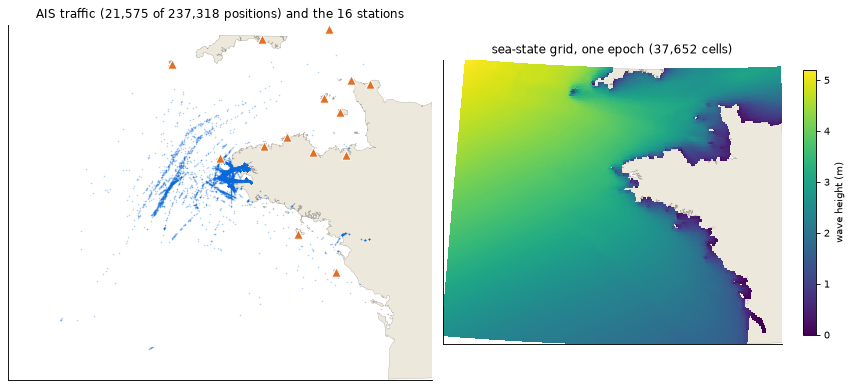

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax in axes:
    coast.plot(ax=ax, color="#ece8dc", edgecolor="#a8a39a", linewidth=0.3)
    ax.set_aspect("equal"); ax.grid(False)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")

thin = ais.iloc[::max(1, len(ais) // 20_000)]
axes[0].scatter(thin.x, thin.y, s=2, c=BLUE, alpha=0.3, linewidths=0)
st = weather.drop_duplicates("station")
axes[0].scatter(st.x, st.y, s=70, marker="^", c=ORANGE, edgecolor="white", linewidth=0.8, zorder=3)
axes[0].set_title(f"AIS traffic ({len(thin):,} of {len(ais):,} positions) and the {len(st)} stations")

one_epoch = ocean[ocean.unix_time == sorted(ocean.unix_time.unique())[len(ocean.unix_time.unique()) // 2]]
sc = axes[1].scatter(one_epoch.x, one_epoch.y, s=6, marker="s", c=one_epoch.wave_height, cmap="viridis", linewidths=0)
fig.colorbar(sc, ax=axes[1], shrink=0.7, label="wave height (m)")
axes[1].set_title(f"sea-state grid, one epoch ({len(one_epoch):,} cells)")

axes[0].set_xlim(ocean.x.min(), ocean.x.max()); axes[0].set_ylim(ocean.y.min(), ocean.y.max())
fig.tight_layout()
savefig(fig, "01_study_area")
plt.show()

### The resolution gap

One vessel's positions against the weather epochs (hourly) and the sea-state epochs (every 3 hours). Every AIS dot between two ticks has no context value of its own; that is the gap annotation fills.

  saved  figures/01_resolution_gap.png  (13 KB)


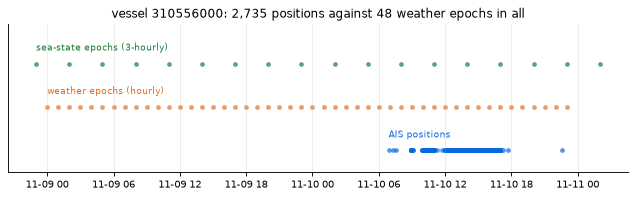

In [4]:
# A vessel to follow through the notebook: of the 20 with most positions, the one that covers
# the largest area (the very busiest may be moored, and a moored vessel has no track to map).
candidates = ais.mmsi.value_counts().index[:20]
extent = ais[ais.mmsi.isin(candidates)].groupby("mmsi").agg(dx=("x", np.ptp), dy=("y", np.ptp))
busiest = int(np.hypot(extent.dx, extent.dy).idxmax())
one = ais[ais.mmsi == busiest].sort_values("unix_time")
STEP = max(1, len(one) // 3000)       # plots thin a long track; every computation uses all points

fig, ax = plt.subplots(figsize=(10, 2.4))
for row, (label, times, color) in enumerate([
        ("AIS positions", one.time.iloc[::STEP], BLUE),
        ("weather epochs (hourly)", pd.to_datetime(sorted(weather[(weather.unix_time >= DEMO[0]) & (weather.unix_time < DEMO[1])].unix_time.unique()), unit="s"), ORANGE),
        ("sea-state epochs (3-hourly)", pd.to_datetime(sorted(ocean.unix_time.unique()), unit="s"), GREEN)]):
    ax.scatter(times, np.full(len(times), row), s=18, c=color, alpha=0.7, linewidths=0)
    ax.text(times.min(), row + 0.25, label, fontsize=8, color=color, va="bottom")
ax.set_yticks([]); ax.set_ylim(-0.5, 2.9)
ax.set_title(f"vessel {busiest}: {len(one):,} positions against {weather.unix_time.nunique()} weather epochs in all")
savefig(fig, "01_resolution_gap")
plt.show()

---
## 2. Stage 1 &mdash; spatial interpolation

Context is measured at stations, never where the moving object is. For each epoch we interpolate the station values **directly to the query position**; no raster is built.

Take a single epoch and look at what the stations recorded: here **mean wind speed**, the `wind_speed` column.

  saved  figures/02_station_snapshot.png  (24 KB)


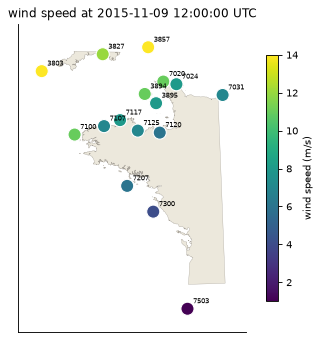

In [5]:
epochs = np.array(sorted(weather.unix_time.unique()))
epoch = epochs[np.searchsorted(epochs, DEMO[0] + 12 * HOUR)]       # midday on the first day
snap = weather[weather.unix_time == epoch]

fig, ax = plt.subplots(figsize=(6.5, 5))
coast.plot(ax=ax, color="#ece8dc", edgecolor="#a8a39a", linewidth=0.3)
sc = ax.scatter(snap.x, snap.y, c=snap.wind_speed, cmap="viridis", s=140, edgecolor="white", zorder=3)
fig.colorbar(sc, ax=ax, shrink=0.8, label="wind speed (m/s)")
for _, r in snap.iterrows():
    ax.annotate(r.station, (r.x, r.y), fontsize=6, xytext=(5, 5), textcoords="offset points")
ax.set_xlim(snap.x.min() - 6e4, snap.x.max() + 6e4); ax.set_ylim(snap.y.min() - 6e4, snap.y.max() + 6e4)
ax.set_aspect("equal"); ax.grid(False); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title(f"wind speed at {pd.to_datetime(epoch, unit='s')} UTC")
savefig(fig, "02_station_snapshot")
plt.show()

### The candidate methods

| | |
|---|---|
| **Nearest** | piecewise constant, an error floor |
| **IDW** | inverse distance weighting, `w = 1/d^p` |
| **TIN** | linear on a Delaunay triangulation |
| **CloughTocher** | cubic C&sup1; on the same triangulation |
| **RBF** | thin-plate spline, smooth |
| **Kriging** | Gaussian process, also returns uncertainty |

All are *exact* at the stations except Kriging with a nugget: a query landing on a station returns that station's value.

In [6]:
centre = (snap.x.mean(), snap.y.mean())
comparison = pd.DataFrame([
    {"method": M.__name__, "estimate_at_centroid": M().fit(snap.x, snap.y, snap.wind_speed)(*centre)}
    for M in (Nearest, IDW, TIN, CloughTocher, RBF, Kriging)
])
fit = IDW().fit(snap.x, snap.y, snap.wind_speed)
print(f"IDW at the first station: {fit(snap.x.iloc[0], snap.y.iloc[0]):.3f}"
      f"  (observed {snap.wind_speed.iloc[0]:.3f})  -- exact at the stations\n")
save_table(comparison, "02_methods_at_centroid")
comparison.round(3)

IDW at the first station: 14.000  (observed 14.000)  -- exact at the stations

  saved  02_methods_at_centroid.csv  (6 rows)


,method,estimate_at_centroid
0,Nearest,7.000
1,IDW,7.362
2,TIN,7.740
3,CloughTocher,7.517
4,RBF,7.469
5,Kriging,7.465


### Surfaces, to see the difference

Annotation samples at points and never needs a raster, but `to_surface` builds one, useful for seeing how the methods differ.

Watch the triangulation methods: they return **nothing outside the convex hull** of the stations. That is deliberate. They have no basis for a value there, and admitting the gap is better than inventing one.

  saved  figures/02_surfaces.png  (177 KB)


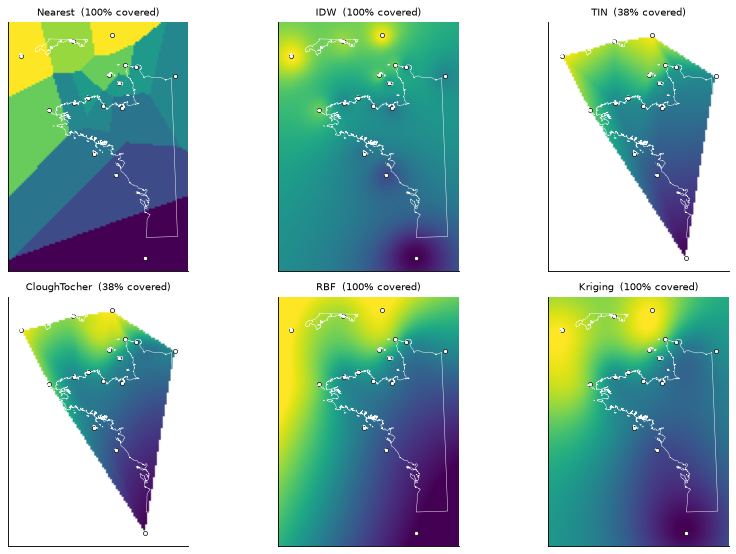

In [7]:
pad = 40_000
bounds = (snap.x.min() - pad, snap.y.min() - pad, snap.x.max() + pad, snap.y.max() + pad)
fig, axes = plt.subplots(2, 3, figsize=(11, 7), sharex=True, sharey=True)
vmin, vmax = snap.wind_speed.min(), snap.wind_speed.max()
for ax, m in zip(axes.ravel(), [Nearest(), IDW(power=2), TIN(), CloughTocher(), RBF(), Kriging()]):
    grid, xs, ys = to_surface(m.fit(snap.x, snap.y, snap.wind_speed), bounds, 6000)
    ax.imshow(grid, origin="lower", extent=(xs.min(), xs.max(), ys.min(), ys.max()),
              cmap="viridis", vmin=vmin, vmax=vmax)
    coast.boundary.plot(ax=ax, color="white", linewidth=0.4)
    ax.scatter(snap.x, snap.y, s=14, c="white", edgecolor="black", linewidth=0.6)
    ax.set_title(f"{type(m).__name__}  ({100 * np.isfinite(grid).mean():.0f}% covered)", fontsize=9)
    ax.set_xlim(bounds[0], bounds[2]); ax.set_ylim(bounds[1], bounds[3])
    ax.set_aspect("equal"); ax.grid(False); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
fig.tight_layout()
savefig(fig, "02_surfaces")
plt.show()

### Which method is best? Leave-one-station-out

Hold out one station, predict its value from the others, compare against what it actually observed. Repeat for every station, at every epoch. This is the spatial analogue of k-fold, with **stations rather than time** as the folds.

Two things get reported that a bare error figure would hide:

- **unreachable predictions**: a held-out station may fall outside the hull of the others. Corner stations often do, and the triangulation methods cannot reach them. A method that fails at edge stations is worse in a way its error alone does not show.
- **station count**: every fit uses one fewer station than exist. With 16 stations, that is thin for kriging.

The epochs are independent, so they are scored in parallel (`n_jobs`). The weather table has all the archive's epochs, not only the days shown in detail.

In [8]:
started = clock.perf_counter()
table = evaluate_spatial(weather.x, weather.y, weather.wind_speed, weather.unix_time, n_jobs=N_JOBS)
print(f"{weather.unix_time.nunique():,} epochs scored in {clock.perf_counter() - started:.0f} s\n")
print(table.summary())

df = table.to_frame()
ranked = (df.groupby("method")[["rmse", "mae", "me", "max_ae", "r2", "unreachable"]]
            .mean().sort_values("rmse"))
save_table(ranked.reset_index(), "02_spatial_cv_ranked")
ranked.round(3)

48 epochs scored in 7 s

leave-one-station-out over 48 epoch(s), 16-16 stations
  tin            mean rmse=1.747   unreachable=288
  clough_tocher  mean rmse=1.902   unreachable=288
  rbf            mean rmse=2.337
  kriging        mean rmse=2.544
  nearest        mean rmse=2.59
  idw            mean rmse=2.66
  saved  02_spatial_cv_ranked.csv  (6 rows)


,rmse,mae,me,max_ae,r2,unreachable
method,,,,,,
tin,1.747,1.436,0.118,3.196,0.430,6.0
clough_tocher,1.902,1.585,0.113,3.620,0.308,6.0
rbf,2.337,1.845,-0.317,5.591,0.351,0.0
kriging,2.544,2.120,0.124,5.373,0.263,0.0
nearest,2.590,2.134,0.158,4.792,0.233,0.0
idw,2.660,2.292,0.144,5.025,0.220,0.0


Five metrics are reported together because no one of them is sufficient:

- **RMSE** and **MAE** are both magnitude-only. A model that consistently under-estimates by 2 m/s scores identically to one scattering &plusmn;2 m/s symmetrically.
- **ME** is signed, so it is the only one that reveals *bias*.
- **Max|e|** exposes rare catastrophic points that RMSE averages away.
- The **gap between RMSE and MAE** is itself diagnostic: a large gap means a few big errors, a small gap means they are spread evenly.

(The wind speed in this archive is stored in whole m/s, which puts a floor under every method's error.)

  saved  figures/02_spatial_cv_by_epoch.png  (74 KB)


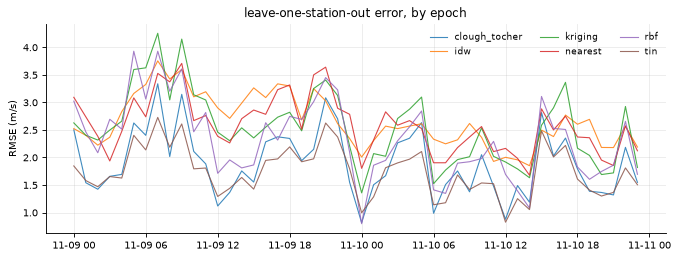

In [9]:
df["time"] = pd.to_datetime(df.epoch, unit="s")
fig, ax = plt.subplots(figsize=(10, 3.4))
for method, g in df.groupby("method"):
    g = g.sort_values("time")
    ax.plot(g.time, g.rmse, label=method, linewidth=1, alpha=0.85)
ax.set_ylabel("RMSE (m/s)"); ax.legend(ncol=3, fontsize=8, frameon=False)
ax.set_title("leave-one-station-out error, by epoch")
savefig(fig, "02_spatial_cv_by_epoch")
plt.show()

That variation is why **per-epoch selection** exists as an option. A calm, smooth field and a storm front are not best served by the same interpolator.

It is not the default, though. The method can then switch between consecutive hours, and a value that moves because the *interpolator* changed rather than the weather is an artefact, one the temporal stage will faithfully reproduce as roughness.

In [10]:
overall = table.select()
per_epoch = table.select(per_epoch=True)
print("one method for all epochs :", overall)
print("\nper-epoch picks:")
print(pd.Series(list(per_epoch.values())).value_counts().to_string())

one method for all epochs : tin

per-epoch picks:
tin              35
clough_tocher    12
rbf               1


### Wind direction is different: it is a bearing

0&deg; and 360&deg; are the same direction. Interpolated as ordinary numbers, stations reading 350&deg; and 10&deg; average to **180&deg;**, the exact opposite heading.

So bearings are interpolated **on the unit circle**: convert each to a vector, interpolate `cos` and `sin` independently, recover with `atan2`. **The caller declares which variables are circular.** Nothing is inferred from a column name.

The weather archive stores direction as a **compass-point code**, not degrees: `degrees = (code - 1) x 22.5` on a 16-point rose (1 is N, 2 is NNE, ... 16 is NNW). Codes 17 (calm), 18 (variable) and 19 (no data) are not directions and become missing values. Interpolating the codes would be meaningless; they are categorical labels, and a step from code 5 to code 13 is not a rotation. The ocean's `wave_direction` is already in degrees.

In [11]:
weather["wind_direction"] = decode_compass(weather.wind_direction_code)
print("codes  :", [int(c) for c in sorted(weather.wind_direction_code.dropna().unique())[:8]])
print("degrees:", [float(d) for d in sorted(weather.wind_direction.dropna().unique())[:8]])

# A worked example that crosses north, where the two treatments diverge.
xs_n, ys_n = np.array([0.0, 1e5, 0.0]), np.array([0.0, 0.0, 1e5])
bearings, q = np.array([350.0, 10.0, 0.0]), (3e4, 3e4)
plain = IDW(circular=False).fit(xs_n, ys_n, bearings)(*q)
circ = IDW(circular=True).fit(xs_n, ys_n, bearings)(*q)
print(f"\nstations reading {bearings.tolist()} degrees:")
print(f"  as plain numbers : {plain:6.1f}   <- the opposite way round, wrong")
print(f"  as bearings      : {circ:6.1f}   <- correct")

codes  : [1, 3, 4, 5, 6, 7, 8, 9]
degrees: [0.0, 45.0, 67.5, 90.0, 112.5, 135.0, 157.5, 180.0]

stations reading [350.0, 10.0, 0.0] degrees:
  as plain numbers :  217.9   <- the opposite way round, wrong
  as bearings      :  355.7   <- correct


### The sea state: a grid is a set of stations

The ocean data are not stations but a **regular grid**: every 3 hours, one value per cell. **The package has no dedicated gridded-input path**: no raster reader, no bilinear lookup in a cell. What it has is spatial interpolation from scattered points, and a grid's cell centres are scattered points like any others. So each cell is passed to `annotate_points` as a *station* (`x`, `y`, `t`, `value`), and nothing new is invented; the sea state is annotated by the same two stages as the weather.

Two things differ from 16 stations:

* **Size.** There are tens of thousands of stations per epoch. The methods that fit a dense system (`RBF`, `Kriging`) need memory and time that grow with the square or cube of that number and are not usable here; `Nearest`, `TIN` and `IDW` are. For IDW we use the `k` nearest cells (`k=4`): with all cells every estimate would be a weighted mean of the whole sea.
* **Validation.** Leave-one-station-out is meaningless with so many cells. Instead, a random set of cells of one epoch is held out and predicted from the rest. This is the *easy* case, since a held-out cell has neighbours a grid step away, so these errors say that a grid is interpolated well between cells, not what the error at a vessel is (that cannot be measured: the forecast is the only sea state there is).

Cells over land are absent or missing and are dropped by the interpolators.

In [12]:
epochs_o = np.array(sorted(ocean.unix_time.unique()))
grid_epoch = ocean[ocean.unix_time == epochs_o[len(epochs_o) // 2]].dropna(subset=["wave_height"]).reset_index(drop=True)
rng = np.random.default_rng(0)
held = np.zeros(len(grid_epoch), bool)
held[rng.choice(len(grid_epoch), 2000, replace=False)] = True
train, test = grid_epoch[~held], grid_epoch[held]
step_km = np.median(np.diff(np.sort(grid_epoch.lon.unique()))) * 111.32 * np.cos(np.radians(48)), \
          np.median(np.diff(np.sort(grid_epoch.lat.unique()))) * 111.32
print(f"{len(grid_epoch):,} cells with a value; grid step about {step_km[0]:.1f} km east-west, "
      f"{step_km[1]:.1f} km north-south; 2,000 held out\n")

rows = []
for name, method in [("Nearest", Nearest()), ("IDW k=4", IDW(power=2, k=4)),
                     ("IDW k=8", IDW(power=2, k=8)), ("TIN", TIN())]:
    began = clock.perf_counter()
    pred = method.fit(train.x, train.y, train.wave_height)(test.x.to_numpy(), test.y.to_numpy())
    rows.append({"method": name, **score(pred, test.wave_height.to_numpy()).as_dict(),
                 "seconds": clock.perf_counter() - began})
grid_cv = pd.DataFrame(rows).set_index("method")
save_table(grid_cv.reset_index(), "02_ocean_holdout")
grid_cv.round(4)

37,652 cells with a value; grid step about 2.5 km east-west, 3.7 km north-south; 2,000 held out



  saved  02_ocean_holdout.csv  (4 rows)


,rmse,mae,me,max_ae,r2,n,seconds
method,,,,,,,
Nearest,0.0618,0.0172,-0.0018,1.8340,0.9961,2000,0.0082
IDW k=4,0.0487,0.0082,0.0008,1.1030,0.9976,2000,0.0092
IDW k=8,0.0514,0.0088,0.0005,1.1589,0.9973,2000,0.0096
TIN,0.0454,0.0055,-0.0001,1.1355,0.9979,1978,0.4783


The errors are small against a wave height of a few metres (the `n` column is the number of held-out cells each method could reach: the triangulation cannot reach cells outside the hull of the others). IDW with a few neighbours is about as good as the triangulation and reaches every point, which matters for a vessel beyond the outermost cell. That is the choice made for the sea state in the rest of the notebook: **IDW with `k=4`**, `power=2`, as for the weather but with `k` limited to the nearest cells.

---
## 3. Stage 2 &mdash; temporal interpolation

Stage 1 gave us a value at the object's position for every epoch. Now we fit a curve through that series and read it at the exact timestamp.

Three candidates, from Mehri et al. (2023) &sect;4.1:

| | | |
|---|---|---|
| **DLT** | Eq. 2 | straight line between consecutive epochs |
| **PiecewisePolynomial** | Eq. 3 | contiguous least-squares windows, degrees 2&ndash;7 |
| **Spline** | Eq. 4 | one cubic curve through every observation |

DLT assumes the variable changes linearly across the gap. Real environmental variables curve, and the coarser the observations the worse a straight line fits, which is what motivates the two nonlinear methods.

The comparison needs one *contiguous* series. On the two-day sample that is the whole station series; on the full archive it is one station over November 2015 (a series spanning the January gap would be fitted across a month with no data).

  saved  figures/03_temporal_methods.png  (38 KB)


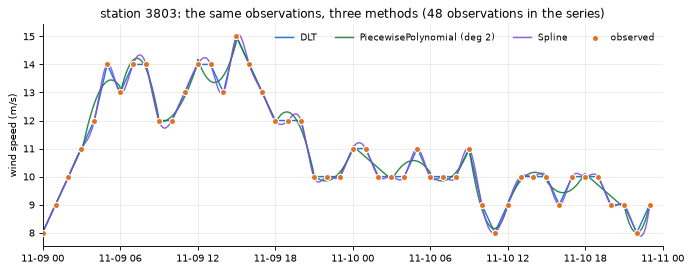

In [13]:
cv_weather = weather[(weather.unix_time >= CV_WINDOW[0]) & (weather.unix_time < CV_WINDOW[1])]
sid = cv_weather.station.iloc[0]
series = cv_weather[cv_weather.station == sid].sort_values("unix_time")
t, v = series.unix_time.to_numpy(float), series.wind_speed.to_numpy(float)
# The observed series every method is fitted to. `fit` drops missing values and collapses
# repeated timestamps to their mean (no curve passes through two values at one instant),
# so do the same here to plot and score exactly what was fitted.
obs = pd.Series(v[np.isfinite(v)]).groupby(t[np.isfinite(v)]).mean()
ts, vs = obs.index.to_numpy(float), obs.to_numpy()
dense = np.linspace(ts.min(), ts.max(), 12 * len(ts))

fits = {"DLT": DLT(), "PiecewisePolynomial (deg 2)": PiecewisePolynomial(degree=2), "Spline": Spline()}
fig, ax = plt.subplots(figsize=(10, 3.6))
for (name, m), color in zip(fits.items(), [BLUE, GREEN, "#8250df"]):
    ax.plot(pd.to_datetime(dense, unit="s"), m.fit(ts, vs)(dense), label=name, color=color, linewidth=1.3, alpha=0.9)
ax.scatter(pd.to_datetime(ts, unit="s"), vs, c=ORANGE, s=30, edgecolor="white", zorder=3, label="observed")
ax.set_xlim(pd.to_datetime(DEMO[0], unit="s"), pd.to_datetime(DEMO[1], unit="s"))   # zoom in: where do they disagree?
ax.set_ylabel("wind speed (m/s)"); ax.legend(ncol=4, fontsize=8, frameon=False)
ax.set_title(f"station {sid}: the same observations, three methods ({len(ts):,} observations in the series)")
savefig(fig, "03_temporal_methods")
plt.show()

Zoom in on the piecewise polynomial and you will see its curve **does not pass through the observations**: it passes *near* them.

That is not a bug. Eq. 3 partitions the interval into contiguous windows, and with `window = degree + 2` each sub-polynomial has `d+1` coefficients fitted to `d+2` points, a least-squares fit with one degree of freedom. A window of exactly `d+1` points would be forced through every one, leaving zero residual and making every degree score identically.

The spline, by contrast, is **interpolating**: it passes through every observation exactly (of the series it was fitted to: missing values are skipped and two readings at one time are averaged first, as `fit` does for every method), and matches slope and curvature at every knot. That difference is what the comparison is really measuring.

In [14]:
residuals = pd.DataFrame([
    {"method": name, "max_abs_residual_at_observations": float(np.abs(m.fit(ts, vs)(ts) - vs).max())}
    for name, m in [("PiecewisePolynomial", PiecewisePolynomial(degree=2)), ("Spline", Spline())]
])
save_table(residuals, "03_interpolating_vs_least_squares")
residuals

  saved  03_interpolating_vs_least_squares.csv  (2 rows)


,method,max_abs_residual_at_observations
0,PiecewisePolynomial,0.6
1,Spline,0.0


### Which method is best? k-fold

Observations are partitioned **randomly** into k sets. Each fold is held out in turn, the rest fits the model, the held-out fold is scored. Reported metrics are the mean over all k folds.

`k` does double duty: training size grows with k, so sweeping k = 2&hellip;10 varies both the fold structure *and* the number of fitting points.

**The first and last observation are always kept in training.** Random partitioning could otherwise hold one out, leaving the training set unable to span it, and the model would be extrapolating, not interpolating. Context observations bracket the trajectory by design, so extrapolation is prevented structurally rather than merely scored.

k-fold over k=2..10, 48 observations
  dlt          best k=10  rmse=0.6395   MAE=0.5275  n_fit=44
  pp_deg2      best k=10  rmse=0.6797   MAE=0.5793  n_fit=44
  spline       best k=9   rmse=0.6903   MAE=0.597  n_fit=43
  pp_deg3      best k=8   rmse=0.8105   MAE=0.6622  n_fit=43
  pp_deg4      best k=8   rmse=0.87   MAE=0.7767  n_fit=43
  pp_deg5      best k=10  rmse=1.015   MAE=0.8147  n_fit=44
  pp_deg6      best k=2   rmse=1.215   MAE=0.9414  n_fit=25
  pp_deg7      best k=8   rmse=1.588   MAE=1.146  n_fit=43


  saved  03_temporal_cv_weather.csv  (72 rows)
  saved  figures/03_temporal_cv_heatmap.png  (15 KB)


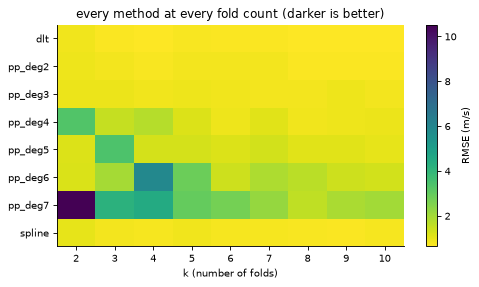

In [15]:
ttable = evaluate_temporal(t, v)
print(ttable.summary())
tf = ttable.to_frame()
save_table(tf, "03_temporal_cv_weather")

heat = tf.pivot(index="method", columns="k", values="rmse")
fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(heat.to_numpy(), cmap="viridis_r", aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns); ax.set_yticks(range(heat.shape[0]), heat.index)
ax.set_xlabel("k (number of folds)"); ax.grid(False)
fig.colorbar(im, label="RMSE (m/s)")
ax.set_title("every method at every fold count (darker is better)")
savefig(fig, "03_temporal_cv_heatmap")
plt.show()

### Selection is deliberately a separate step

`evaluate_temporal` returns the table; the analyst chooses. The published study shows why that is not purely mechanical: for mean wind speed, DLT won on MAE while the spline won on RMSE, and the spline was chosen *because* RMSE weights the large errors that matter for this application.

`select()` returns the winner **already fitted to every observation**, ready to annotate with.

In [16]:
by_rmse, by_mae = ttable.best_row("rmse"), ttable.best_row("mae")
print(f"best by RMSE: {by_rmse.method} (k={by_rmse.k})")
print(f"best by MAE : {by_mae.method} (k={by_mae.k})")
if (by_rmse.method, by_rmse.k) != (by_mae.method, by_mae.k):
    print("\n-> they disagree; the choice is a judgement, not a default")
model = ttable.select()          # or ttable.select(method="spline")
print(f"\nselected and fitted: {model}")

best by RMSE: dlt (k=10)
best by MAE : dlt (k=10)

selected and fitted: DLT(circular=False)


### The sea state is coarser in time

The same comparison for a context that arrives only every 3 hours: the forecast wave height at the grid cell nearest to the mean position of the vessel followed in this notebook. The coarser the epochs, the more the shape of the curve between them matters.

In [17]:
cells_xy = ocean.drop_duplicates(["lon", "lat"])
d2 = (cells_xy.x - one.x.mean()) ** 2 + (cells_xy.y - one.y.mean()) ** 2
cell = cells_xy.loc[d2.idxmin()]
parts = [pd.read_parquet(f, columns=["unix_time", "wave_height"],
                         filters=[("lon", "==", cell.lon), ("lat", "==", cell.lat),
                                  ("unix_time", ">=", CV_WINDOW[0]), ("unix_time", "<", CV_WINDOW[1])])
         for f in sorted((ROOT / "Ocean").glob("ocean_*.parquet"))]
cell_series = pd.concat(parts).drop_duplicates("unix_time").sort_values("unix_time")
to_, vo_ = cell_series.unix_time.to_numpy(float), cell_series.wave_height.to_numpy(float)

otable = evaluate_temporal(to_, vo_)
print(f"grid cell at lon {cell.lon:.3f}, lat {cell.lat:.3f}: {len(to_)} three-hourly values\n")
print(otable.summary())
save_table(otable.to_frame(), "03_temporal_cv_wave_height")

grid cell at lon -4.900, lat 48.233: 16 three-hourly values

k-fold over k=2..10, 16 observations
  pp_deg6      best k=10  rmse=0.00951   MAE=0.008906  n_fit=15
  spline       best k=6   rmse=0.01048   MAE=0.009402  n_fit=14
  pp_deg7      best k=10  rmse=0.01096   MAE=0.01034  n_fit=15
  pp_deg5      best k=10  rmse=0.01466   MAE=0.01411  n_fit=15
  pp_deg3      best k=10  rmse=0.01932   MAE=0.01792  n_fit=15
  pp_deg4      best k=10  rmse=0.02096   MAE=0.0193  n_fit=15
  pp_deg2      best k=10  rmse=0.02661   MAE=0.02635  n_fit=15
  dlt          best k=10  rmse=0.03019   MAE=0.0288  n_fit=15
  saved  03_temporal_cv_wave_height.csv  (72 rows)


---
## 4. Putting it together

`annotate_points` runs both stages: spatial across stations (or grid cells) at each epoch, then temporal through the resulting series. The stations table needs four columns: `x`, `y`, `t`, `value`, whatever the source called them.

Eight context variables are annotated, four from the weather stations and four from the sea-state grid:

| variable | source | unit | circular | spatial method |
|---|---|---|---|---|
| `wind_speed`, `air_temperature`, `air_pressure` | weather | m/s, &deg;C, mmHg | no | IDW, power 2 |
| `wind_direction` | weather | degrees | **yes** | IDW, power 2, on the unit circle |
| `sea_level`, `wave_height`, `wave_length` | ocean grid | m | no | IDW, power 2, `k=4` |
| `wave_direction` | ocean grid | degrees | **yes** | IDW, `k=4`, on the unit circle |

In this section and the next, one vessel is annotated with a **spline** (the temporal method that won on RMSE above), the way the study did. Every position is annotated, no sampling. Each epoch's spatial interpolator is fitted once and evaluated at all positions together.

In [18]:
# name: (source, column, circular, unit)
VARIABLES = {
    "wind_speed":      ("weather", "wind_speed", False, "m/s"),
    "air_temperature": ("weather", "air_temperature", False, "degC"),
    "air_pressure":    ("weather", "air_pressure", False, "mmHg"),
    "wind_direction":  ("weather", "wind_direction", True, "degrees"),   # a bearing, from the compass code
    "sea_level":       ("ocean", "sea_level", False, "m"),
    "wave_height":     ("ocean", "wave_height", False, "m"),
    "wave_length":     ("ocean", "wave_length", False, "m"),
    "wave_direction":  ("ocean", "wave_direction", True, "degrees"),     # a bearing
}

def spatial_for(source, circular):
    # IDW everywhere; the grid's tens of thousands of cells use their 4 nearest only.
    return IDW(power=2, circular=circular) if source == "weather" else IDW(power=2, k=4, circular=circular)

def context_rows(source, w, o):
    return w if source == "weather" else o

track = one.copy()                          # every point of the followed vessel, not a sample
tx, ty, tt = track.x.to_numpy(), track.y.to_numpy(), track.unix_time.to_numpy(float)

began = clock.perf_counter()
for name in ("wind_speed", "wave_height"):
    source, col, circular, unit = VARIABLES[name]
    track[name] = annotate_points(
        stations_of(context_rows(source, weather, ocean), col), tx, ty, tt,
        spatial_method=spatial_for(source, circular), temporal_method=Spline(circular=circular),
        circular=circular, chunk_epochs=None, n_jobs=N_JOBS, filter_window=None)
print(f"annotated {track.wind_speed.notna().sum():,}/{len(track):,} positions of vessel {busiest} "
      f"with a spline in {clock.perf_counter() - began:.0f} s")
track[["time", "speed_over_ground", "wind_speed", "wave_height"]].head()

annotated 2,735/2,735 positions of vessel 310556000 with a spline in 1 s


,time,speed_over_ground,wind_speed,wave_height
213316,2015-11-10 06:53:37,15.200000,7.022509,3.328197
213317,2015-11-10 07:18:24,15.500000,6.954155,3.369844
213318,2015-11-10 07:32:37,15.400000,6.896147,3.392814
213319,2015-11-10 08:54:48,14.800000,6.641475,3.488900
213320,2015-11-10 08:55:19,14.799999,6.639257,3.490256


The track on the coastline, coloured by what the annotation gave it: the wind it was moving through, and the wave height. The stations are the orange triangles.

  saved  figures/04_annotated_track_map.png  (38 KB)


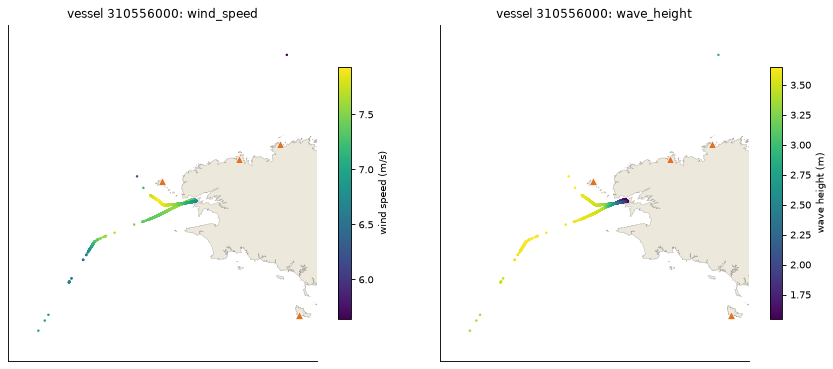

In [19]:
shown = track.iloc[::STEP]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, name, label in zip(axes, ("wind_speed", "wave_height"), ("wind speed (m/s)", "wave height (m)")):
    coast.plot(ax=ax, color="#ece8dc", edgecolor="#a8a39a", linewidth=0.3)
    sc = ax.scatter(shown.x, shown.y, c=shown[name], cmap="viridis", s=5, linewidths=0, zorder=2)
    ax.scatter(st.x, st.y, s=50, marker="^", c=ORANGE, edgecolor="white", linewidth=0.6, zorder=3)
    fig.colorbar(sc, ax=ax, shrink=0.75, label=label)
    ax.set_title(f"vessel {busiest}: {name}")
    ax.set_aspect("equal"); ax.grid(False); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
pad = 3e4
axes[0].set_xlim(track.x.min() - pad, track.x.max() + pad); axes[0].set_ylim(track.y.min() - pad, track.y.max() + pad)
fig.tight_layout()
savefig(fig, "04_annotated_track_map")
plt.show()

The annotated series is smooth and follows the regional trend, but it is **not** the station mean: it tracks conditions along *this vessel's* path, which is the whole point. The same holds for the waves against the mean of the whole grid.

  saved  figures/04_context_along_path.png  (36 KB)


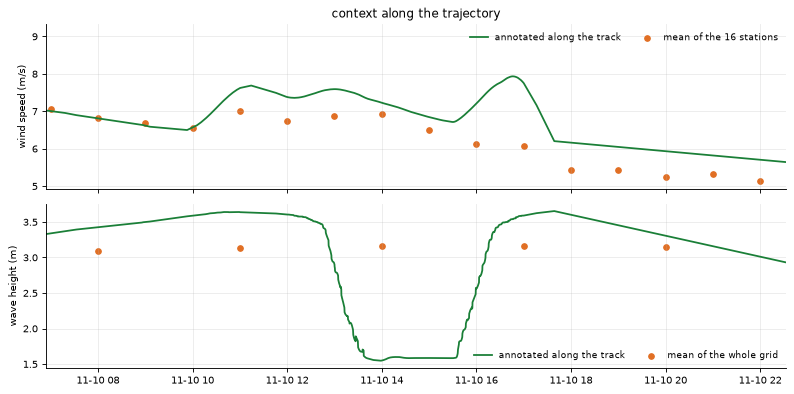

In [20]:
station_mean = weather[(weather.unix_time >= DEMO[0]) & (weather.unix_time < DEMO[1])].groupby("time").wind_speed.mean()
grid_mean = ocean.groupby("time").wave_height.mean()

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(shown.time, shown.wind_speed, color=GREEN, linewidth=1.6, label="annotated along the track")
axes[0].scatter(station_mean.index, station_mean.values, c=ORANGE, s=25, label=f"mean of the {weather.station.nunique()} stations")
axes[0].set_ylabel("wind speed (m/s)")
axes[1].plot(shown.time, shown.wave_height, color=GREEN, linewidth=1.6, label="annotated along the track")
axes[1].scatter(grid_mean.index, grid_mean.values, c=ORANGE, s=25, label="mean of the whole grid")
axes[1].set_ylabel("wave height (m)")
axes[1].set_xlim(shown.time.min(), shown.time.max())
for ax in axes:
    ax.legend(fontsize=8, frameon=False, ncol=2)
axes[0].set_title("context along the trajectory")
fig.tight_layout()
savefig(fig, "04_context_along_path")
plt.show()

### With MovingPandas

`annotate` writes onto a trajectory's dataframe. Because context lives as an ordinary column, it survives the `.iloc` slicing that trajectory compression performs, so a compressed trajectory keeps the context of the points it retains.

In [21]:
import geopandas as gpd
import movingpandas as mpd

gtrack = gpd.GeoDataFrame(track, geometry=gpd.points_from_xy(track.x, track.y), crs=CRS)
traj = mpd.Trajectory(gtrack.set_index("time"), traj_id=str(busiest))
annotate(traj, stations_of(weather, "wind_speed"), "wind_speed_mpd",
         spatial_method=IDW(power=2), temporal_method=Spline(), chunk_epochs=None,
         n_jobs=N_JOBS, filter_window=None)

print(traj)
print("identical to annotate_points:", np.allclose(traj.df.wind_speed_mpd, track.set_index("time").wind_speed, equal_nan=True))
traj.df[["speed_over_ground", "wind_speed_mpd"]].head()

C:\Users\saeed\miniconda3\envs\catraj\Lib\site-packages\movingpandas\__init__.py:41: UserWarning: Missing optional dependencies. To use the trajectory smoother classes please install Stone Soup (see https://stonesoup.readthedocs.io/en/latest/#installation).
  warnings.warn(e.msg, UserWarning)


Trajectory 310556000 (2015-11-10 06:53:37 to 2015-11-10 22:33:15) | Size: 2735 | Length: 477.2 km
Bounds: (225970.0884791384, 5223327.629276063, 471641.24039816257, 5495981.680412759)
LINESTRING (225970.0884791384 5223327.629276063, 232301.7427712336 5233296.070834133, 235935.3947536
identical to annotate_points: True


,speed_over_ground,wind_speed_mpd
time,,
2015-11-10 06:53:37,15.200000,7.022509
2015-11-10 07:18:24,15.500000,6.954155
2015-11-10 07:32:37,15.400000,6.896147
2015-11-10 08:54:48,14.800000,6.641475
2015-11-10 08:55:19,14.799999,6.639257


---
## 5. All eight variables on one vessel

Each context variable gets its own choice of method, and `circular=True` where the variable is a bearing. The panels share a time axis, so a wind shift can be read against the pressure change that accompanied it.

In [22]:
began = clock.perf_counter()
for name, (source, col, circular, unit) in VARIABLES.items():
    if name in track:
        continue
    track[name] = annotate_points(
        stations_of(context_rows(source, weather, ocean), col), tx, ty, tt,
        spatial_method=spatial_for(source, circular), temporal_method=Spline(circular=circular),
        circular=circular, chunk_epochs=None, n_jobs=N_JOBS, filter_window=None)
print(f"{len(VARIABLES)} variables in {clock.perf_counter() - began:.0f} s\n")
print(track[list(VARIABLES)].describe().loc[["count", "mean", "min", "max"]].round(2).T.to_string())

8 variables in 5 s

                  count    mean     min     max
wind_speed       2735.0    7.33    5.64    7.93
air_temperature  2735.0   14.42   12.29   14.73
air_pressure     2735.0  770.04  769.21  770.51
wind_direction   2735.0  225.72  223.31  233.92
sea_level        2735.0    1.02    0.00    1.56
wave_height      2735.0    2.70    1.55    3.65
wave_length      2735.0  150.99  111.47  197.17
wave_direction   2735.0  259.31  239.34  276.50


  saved  figures/05_all_variables_one_vessel.png  (86 KB)


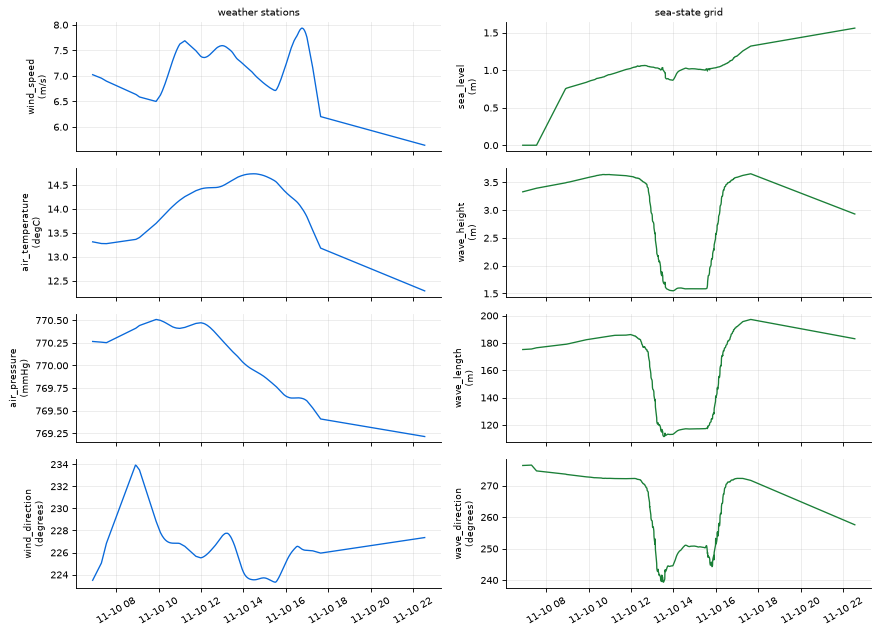

In [23]:
fig, axes = plt.subplots(4, 2, figsize=(11, 8), sharex=True)
for ax, (name, (source, _, circular, unit)) in zip(axes.T.ravel(), VARIABLES.items()):
    ax.plot(shown.time, track.loc[shown.index, name], color=BLUE if source == "weather" else GREEN, linewidth=1.2)
    ax.set_ylabel(f"{name}\n({unit})", fontsize=8)
for ax in axes[-1]:
    ax.tick_params(axis="x", rotation=30)
axes[0, 0].set_title("weather stations", fontsize=9); axes[0, 1].set_title("sea-state grid", fontsize=9)
fig.tight_layout()
savefig(fig, "05_all_variables_one_vessel")
plt.show()

---
## 6. Every vessel

Sections 4 and 5 annotated one trajectory. `annotate_points` takes any number of positions, so the same call annotates the whole fleet: **every AIS point of every vessel** of the chosen dataset. The result is written to `annotated_ais.parquet`.

Choices for a run this size:

* **Spatial: IDW.** TIN scored best in the leave-one-station-out comparison above, but it returns nothing outside the hull of the stations, and much of the traffic lies offshore of it (the table showed how many held-out stations were unreachable). IDW reaches every position. For the grid, IDW with the 4 nearest cells, as validated above.
* **Temporal: DLT**, a straight line between consecutive epochs. A spline is fitted position by position; DLT is evaluated for all positions at once, so millions of positions take minutes rather than hours. Compare the two on the vessel followed in sections 4 and 5 at the end of the section.
* **`filter_window=None`**: the preprocessed context is already median-filtered.
* **Time blocks.** `chunk_epochs` splits the positions into blocks of 12 weather epochs (12 h) and 8 sea-state epochs (24 h); the blocks run on `N_JOBS` processes (see *Parallel processing*). For DLT the result is identical to one pass over the whole period, since DLT only uses the two epochs on either side of a point.
* **Period by period.** The positions are processed one period at a time (the whole sample, or one calendar month of the archive). Each period reads its own AIS rows, the weather and grid rows from two epochs (6 h) before it to two after it, so points at the start and end of a month have the epochs on both sides, and appends its rows to the Parquet file before the next one starts. **No period reaches across the January 2016 gap**: December's last positions are annotated from December's last epoch, held, since the next one is a month away and belongs to February.
* **Storage.** Context columns are stored as 32-bit floats (more digits than the data has), which halves the file.

In [24]:
AIS_COLUMNS = ["mmsi", "unix_time", "lon", "lat", "x", "y", "speed_over_ground", "vessel_type"]
OCEAN_COLUMNS = ["unix_time", "lon", "lat"] + [c for s, c, _, _ in VARIABLES.values() if s == "ocean"]
CHUNK = {"weather": 12, "ocean": 8}             # epochs per time block
MARGIN = 2 * THREE_HOURS                         # context read this far either side of a period

def read_ocean_columns(lo, hi):
    files = sorted((ROOT / "Ocean").glob("ocean_*.parquet"))
    parts = [pd.read_parquet(f, columns=OCEAN_COLUMNS,
                             filters=[("unix_time", ">=", lo), ("unix_time", "<=", hi)]) for f in files]
    o = pd.concat([p for p in parts if len(p)], ignore_index=True)
    o = o.drop_duplicates(["unix_time", "lon", "lat"], ignore_index=True)
    o["x"], o["y"] = Transformer.from_crs(4326, CRS, always_xy=True).transform(o.lon.to_numpy(), o.lat.to_numpy())
    return o

def vessel_partials(pts):
    # Per-vessel sums of one period: enough to build the whole-run means afterwards.
    g = pts.groupby("mmsi")
    out = pd.DataFrame({"positions": g.size(), "first_time": g.unix_time.min(), "last_time": g.unix_time.max(),
                        "vessel_type": g.vessel_type.first()})
    for name, (_, _, circular, _) in VARIABLES.items():
        v = pts[name].astype(float)
        out[f"{name}__n"] = v.notna().groupby(pts.mmsi).sum()
        if circular:
            rad = np.radians(v)
            out[f"{name}__sin"] = np.sin(rad).groupby(pts.mmsi).sum()
            out[f"{name}__cos"] = np.cos(rad).groupby(pts.mmsi).sum()
        else:
            out[f"{name}__sum"] = v.groupby(pts.mmsi).sum()
    return out

def annotate_period(lo, hi):
    pts = read_ais(lo, hi, AIS_COLUMNS)
    w = weather[(weather.unix_time >= lo - MARGIN) & (weather.unix_time <= hi + MARGIN)]
    o = read_ocean_columns(lo - MARGIN, hi + MARGIN)
    x, y, t = pts.x.to_numpy(), pts.y.to_numpy(), pts.unix_time.to_numpy(float)
    seconds = {}
    for name, (source, col, circular, unit) in VARIABLES.items():
        began = clock.perf_counter()
        pts[name] = annotate_points(
            stations_of(context_rows(source, w, o), col), x, y, t,
            spatial_method=spatial_for(source, circular), temporal_method=DLT(circular=circular),
            circular=circular, chunk_epochs=CHUNK[source], n_jobs=N_JOBS, filter_window=None,
        ).astype("float32")
        seconds[name] = clock.perf_counter() - began
    return pts, seconds

OUT = RESULTS / "annotated_ais.parquet"
OUT.unlink(missing_ok=True)
writer, schema = None, None
partials, timing, fleet_sample = [], [], []
MAP_POINTS = 30_000 // len(PERIODS)             # a map needs a sample, not millions

run_began = clock.perf_counter()
for label, lo, hi in PERIODS:
    began = clock.perf_counter()
    pts, seconds = annotate_period(lo, hi)
    table_ = pa.Table.from_pandas(pts, preserve_index=False)
    if writer is None:
        schema = table_.schema
        writer = pq.ParquetWriter(OUT, schema, compression="zstd")
    writer.write_table(table_.cast(schema), row_group_size=1_000_000)
    partials.append(vessel_partials(pts))
    fleet_sample.append(pts.iloc[::max(1, len(pts) // MAP_POINTS)][["x", "y", "wind_speed", "wave_height"]])
    timing.append({"period": label, "positions": len(pts), "vessels": pts.mmsi.nunique(),
                   **{f"{k}_s": round(v, 1) for k, v in seconds.items()},
                   **{f"{k}_annotated": round(float(pts[k].notna().mean()), 4) for k in VARIABLES},
                   "total_s": round(clock.perf_counter() - began, 1)})
    print(f"{label:<26} {len(pts):>10,} positions {pts.mmsi.nunique():>5,} vessels  "
          f"{clock.perf_counter() - began:6.0f} s   "
          f"annotated: wind {pts.wind_speed.notna().mean():.2%}, waves {pts.wave_height.notna().mean():.2%}")
    del pts
writer.close()

timing = pd.DataFrame(timing)
save_table(timing, "annotation_timing")
total = clock.perf_counter() - run_began
print(f"\n{timing.positions.sum():,} positions, {total:.0f} s in all ({timing.positions.sum() / total:,.0f} positions/s, "
      f"N_JOBS={N_JOBS}); {OUT.name}: {OUT.stat().st_size / 2**20:.1f} MB")

2015-11-09 to 2015-11-10      237,318 positions   565 vessels      10 s   annotated: wind 100.00%, waves 100.00%
  saved  annotation_timing.csv  (1 rows)

237,318 positions, 10 s in all (23,125 positions/s, N_JOBS=-1); annotated_ais.parquet: 14.5 MB


Per variable: how many positions were annotated (NaN means the context had no value for any station or cell near that epoch) and what each variable cost, per period.

In [25]:
cols = [c for c in timing.columns if c.endswith("_annotated")]
print((timing.set_index("period")[cols].rename(columns=lambda c: c.replace("_annotated", ""))).T.to_string(float_format=lambda f: f"{f:.2%}"))
print()
print(timing.set_index("period")[[c for c in timing.columns if c.endswith("_s")]].T.to_string())

period           2015-11-09 to 2015-11-10
wind_speed                        100.00%
air_temperature                   100.00%
air_pressure                      100.00%
wind_direction                    100.00%
sea_level                         100.00%
wave_height                       100.00%
wave_length                       100.00%
wave_direction                    100.00%

period             2015-11-09 to 2015-11-10
wind_speed_s                            0.8
air_temperature_s                       0.8
air_pressure_s                          0.8
wind_direction_s                        1.8
sea_level_s                             1.1
wave_height_s                           1.1
wave_length_s                           1.2
wave_direction_s                        2.1
total_s                                10.3


### The per-vessel summary

One row per vessel: its positions, first and last time, and the mean of every context variable over its positions (a bearing's mean is taken on the circle). Built from the per-period partial sums, so the full table was never in memory.

In [26]:
allp = pd.concat(partials)
by = allp.groupby(level=0)
summary = by.agg(positions=("positions", "sum"), first_time=("first_time", "min"), last_time=("last_time", "max"),
                 vessel_type=("vessel_type", "first"))
for name, (_, _, circular, _) in VARIABLES.items():
    n = by[f"{name}__n"].sum()
    if circular:
        s, c = by[f"{name}__sin"].sum(), by[f"{name}__cos"].sum()
        summary[f"mean_{name}"] = np.mod(np.degrees(np.arctan2(s, c)), 360).where(n > 0)
    else:
        summary[f"mean_{name}"] = (by[f"{name}__sum"].sum() / n).where(n > 0)
summary["first_time"] = pd.to_datetime(summary.first_time, unit="s")
summary["last_time"] = pd.to_datetime(summary.last_time, unit="s")
summary = summary.sort_values("positions", ascending=False).reset_index()
summary[summary.select_dtypes("float").columns] = summary.select_dtypes("float").round(2)
summary.to_csv(RESULTS / "vessel_summary.csv", index=False)
del partials, allp
print(f"{len(summary):,} vessels, {summary.positions.sum():,} positions -> vessel_summary.csv")
summary.head(8)

565 vessels, 237,318 positions -> vessel_summary.csv


,mmsi,positions,first_time,last_time,vessel_type,mean_wind_speed,mean_air_temperature,mean_air_pressure,mean_wind_direction,mean_sea_level,mean_wave_height,mean_wave_length,mean_wave_direction
0,228068600,17461,2015-11-09 00:00:04,2015-11-10 23:59:51,Cargo,7.19,13.54,770.26,226.44,0.75,1.40,88.84,239.65
1,228186700,17111,2015-11-09 00:00:03,2015-11-10 23:59:54,SAR,7.25,13.51,770.25,227.02,0.76,1.42,90.95,239.71
2,228051000,17009,2015-11-09 00:00:08,2015-11-10 23:59:59,Tug,7.15,13.50,770.25,226.42,0.78,1.43,91.19,239.97
3,227003050,14364,2015-11-09 00:00:05,2015-11-10 23:59:46,Passenger,7.09,13.44,770.20,226.68,0.78,1.43,91.78,239.98
4,227705102,12266,2015-11-09 05:47:40,2015-11-10 23:59:53,Passenger,7.22,13.64,770.41,224.02,0.76,1.43,91.31,239.85
5,227574020,10867,2015-11-09 00:00:13,2015-11-10 23:59:52,Passenger,7.26,13.62,770.40,225.93,0.74,1.38,88.04,239.51
6,311027900,8497,2015-11-09 00:00:04,2015-11-10 01:50:23,Tanker,7.96,13.17,770.33,230.82,0.87,1.80,88.38,244.14
7,306872000,7556,2015-11-09 00:00:03,2015-11-10 03:43:23,Cargo,7.95,13.43,770.32,230.50,0.80,1.57,79.96,241.12


### A few vessels, and the whole fleet

The annotated file is read back for the busiest vessel of each of the four most common vessel types (only their rows are read: Parquet filters on the vessel, so this stays cheap on the full archive), and a sample of the whole fleet that was kept while annotating is mapped.

  saved  figures/06_a_few_vessels.png  (46 KB)


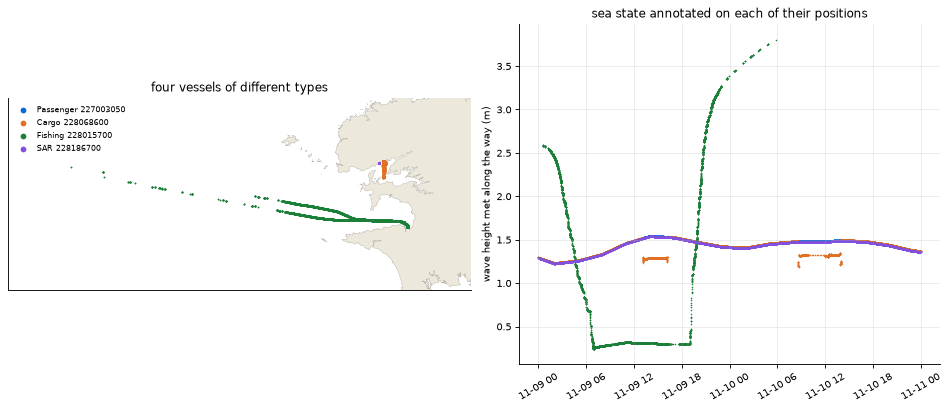

vessel 310556000, spline against DLT on 2,735 common positions:
  wind_speed   mean |difference| 0.075, largest 0.265
  wave_height  mean |difference| 0.003, largest 0.006


In [27]:
top_types = summary.groupby("vessel_type").positions.sum().sort_values(ascending=False).index[:4]
chosen = [summary[summary.vessel_type == vt].iloc[0] for vt in top_types]
ids = [int(r.mmsi) for r in chosen]
few = pd.read_parquet(OUT, columns=["mmsi", "unix_time", "x", "y", "wind_speed", "wave_height"],
                      filters=[("mmsi", "in", ids)])
few["time"] = pd.to_datetime(few.unix_time, unit="s")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
coast.plot(ax=axes[0], color="#ece8dc", edgecolor="#a8a39a", linewidth=0.3)
colors = [BLUE, ORANGE, GREEN, "#8250df"]
for r, color in zip(chosen, colors):
    g = few[few.mmsi == int(r.mmsi)]
    g = g.iloc[::max(1, len(g) // 4000)]
    axes[0].scatter(g.x, g.y, s=3, c=color, linewidths=0, label=f"{r.vessel_type} {int(r.mmsi)}")
    axes[1].scatter(g.time, g.wave_height, s=2, c=color, linewidths=0)
axes[0].legend(fontsize=7, markerscale=3, loc="upper left", frameon=False)
axes[0].set_xlim(few.x.min() - 3e4, few.x.max() + 3e4); axes[0].set_ylim(few.y.min() - 3e4, few.y.max() + 3e4)
axes[0].set_aspect("equal"); axes[0].grid(False); axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].set_xlabel(""); axes[0].set_ylabel("")
axes[0].set_title("four vessels of different types")
axes[1].set_ylabel("wave height met along the way (m)"); axes[1].tick_params(axis="x", rotation=30)
axes[1].set_title("sea state annotated on each of their positions")
fig.tight_layout()
savefig(fig, "06_a_few_vessels")
plt.show()

# The vessel followed in sections 4 and 5, annotated with DLT in the file and with a spline in section 5.
same = few[few.mmsi == busiest] if busiest in ids else pd.read_parquet(
    OUT, columns=["unix_time", "wind_speed", "wave_height"],
    filters=[("mmsi", "==", int(busiest)), ("unix_time", ">=", DEMO[0]), ("unix_time", "<", DEMO[1])])
both = track[["unix_time", "wind_speed", "wave_height"]].merge(same[["unix_time", "wind_speed", "wave_height"]],
                                                               on="unix_time", suffixes=("_spline", "_dlt"))
print(f"vessel {busiest}, spline against DLT on {len(both):,} common positions:")
for v_ in ("wind_speed", "wave_height"):
    d = (both[f"{v_}_spline"] - both[f"{v_}_dlt"]).abs()
    print(f"  {v_:<12} mean |difference| {d.mean():.3f}, largest {d.max():.3f}")

  saved  figures/06_fleet_map.png  (97 KB)


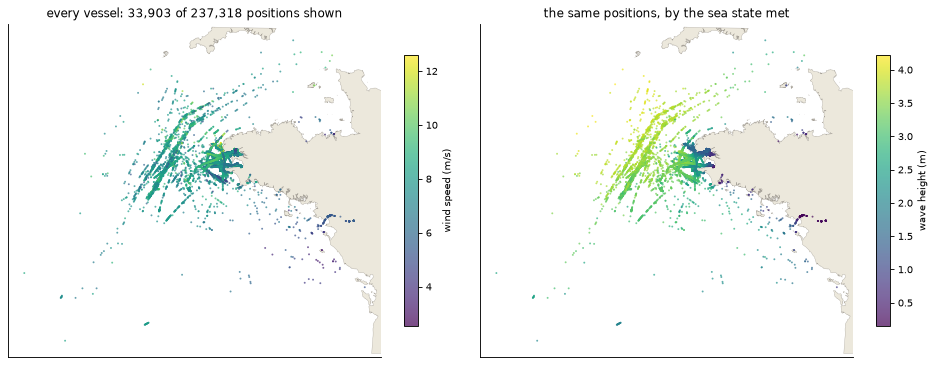

In [28]:
fleet_map = pd.concat(fleet_sample, ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
for ax, name, label in zip(axes, ("wind_speed", "wave_height"), ("wind speed (m/s)", "wave height (m)")):
    coast.plot(ax=ax, color="#ece8dc", edgecolor="#a8a39a", linewidth=0.3)
    sc = ax.scatter(fleet_map.x, fleet_map.y, c=fleet_map[name], s=3, cmap="viridis", linewidths=0, alpha=0.7)
    fig.colorbar(sc, ax=ax, shrink=0.75, label=label)
    ax.set_aspect("equal"); ax.grid(False); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
axes[0].set_xlim(fleet_map.x.min() - 3e4, fleet_map.x.max() + 3e4); axes[0].set_ylim(fleet_map.y.min() - 3e4, fleet_map.y.max() + 3e4)
axes[0].set_title(f"every vessel: {len(fleet_map):,} of {timing.positions.sum():,} positions shown")
axes[1].set_title("the same positions, by the sea state met")
fig.tight_layout()
savefig(fig, "06_fleet_map")
plt.show()

---
## What was saved

Everything is in `results/02_trajectory_annotation/<DATA>/`: the annotated AIS (one Parquet file, readable with `pandas.read_parquet`, DuckDB, QGIS; `x`, `y` are UTM 30N metres, `lon`, `lat` degrees), the per-vessel summary, the timing and cross-validation tables, and the figures. The folder is git-ignored; the notebook regenerates it.

In [29]:
manifest = pd.DataFrame([{"file": f.relative_to(RESULTS).as_posix(), "size_kb": round(f.stat().st_size / 1024, 1)}
                         for f in sorted(RESULTS.rglob("*")) if f.is_file()])
manifest.to_csv(RESULTS / "00_manifest.csv", index=False)
print(f"{len(manifest)} files, {manifest.size_kb.sum() / 1024:.1f} MB in {RESULTS.relative_to(REPO).as_posix()}/")
manifest

22 files, 15.3 MB in results/02_trajectory_annotation/sample/


,file,size_kb
0,00_manifest.csv,0.7
1,02_methods_at_centroid.csv,0.2
2,02_ocean_holdout.csv,0.6
3,02_spatial_cv_ranked.csv,0.7
4,03_interpolating_vs_least_squares.csv,0.1
5,03_temporal_cv_wave_height.csv,8.4
6,03_temporal_cv_weather.csv,7.9
7,annotated_ais.parquet,14884.9
8,annotation_timing.csv,0.4
9,figures/01_resolution_gap.png,13.2
